# Lab 4 - Text-to-Image & Latent Space Exploration
**COM SCI-X 455 - Week 4 - Megan Armani, PhD**

> Push to `genai-course/week4/`  |  GPU: T4 or A10G required (Runtime > Change runtime type > T4 GPU)

---
Note: `xformers` is not installed because it pins a different torch build than Colab ships; diffusers uses
PyTorch scaled-dot-product attention instead, which gives the same memory saving. The fp16-fixed SDXL VAE
(`madebyollin/sdxl-vae-fp16-fix`) is used so fp16 decoding does not produce black/NaN images.

## Setup

In [1]:
!pip install -q -U diffusers
!pip install -q open-clip-torch tabulate

In [2]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import torch, time
from diffusers import (StableDiffusionXLPipeline, DPMSolverMultistepScheduler,
                       StableDiffusionXLControlNetPipeline, ControlNetModel,
                       DDIMScheduler, AutoencoderKL)
from PIL import Image
import numpy as np, matplotlib.pyplot as plt, pandas as pd

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE == "cuda", "Switch the runtime to a GPU (T4)"
print("Device:", DEVICE, "| VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
os.makedirs("lab4_images", exist_ok=True)

def show_row(images, titles, path=None, size=4):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=11); ax.axis("off")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig

Device: cuda | VRAM: 15.6 GB


## Part 1 - SDXL Pipeline + CFG Sweep

In [3]:
# Load SDXL + Canny ControlNet ONCE (fp16). `pipe` (plain SDXL) and `pipe_cn` share the same weights,
# so only one copy sits on the T4. Loading two separate pipelines ran out of memory.
import gc
vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
controlnet = ControlNetModel.from_pretrained("diffusers/controlnet-canny-sdxl-1.0", torch_dtype=torch.float16, variant="fp16")
pipe_cn = StableDiffusionXLControlNetPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0", vae=vae, controlnet=controlnet,
    torch_dtype=torch.float16, variant="fp16", use_safetensors=True).to(DEVICE)
pipe_cn.set_progress_bar_config(disable=True)

pipe = StableDiffusionXLPipeline.from_pipe(pipe_cn, torch_dtype=torch.float16) # no copy: same UNet / text encoders / VAE
print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB")
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
print("SDXL loaded")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


GPU memory in use: 9.4 GB
SDXL loaded


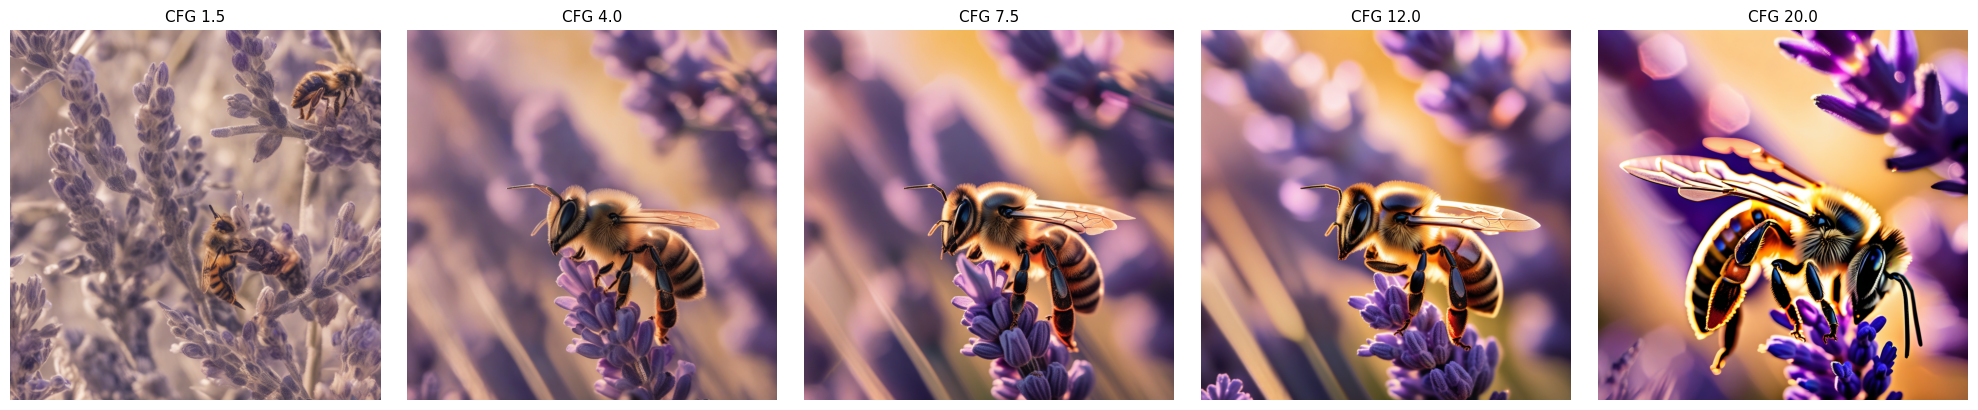

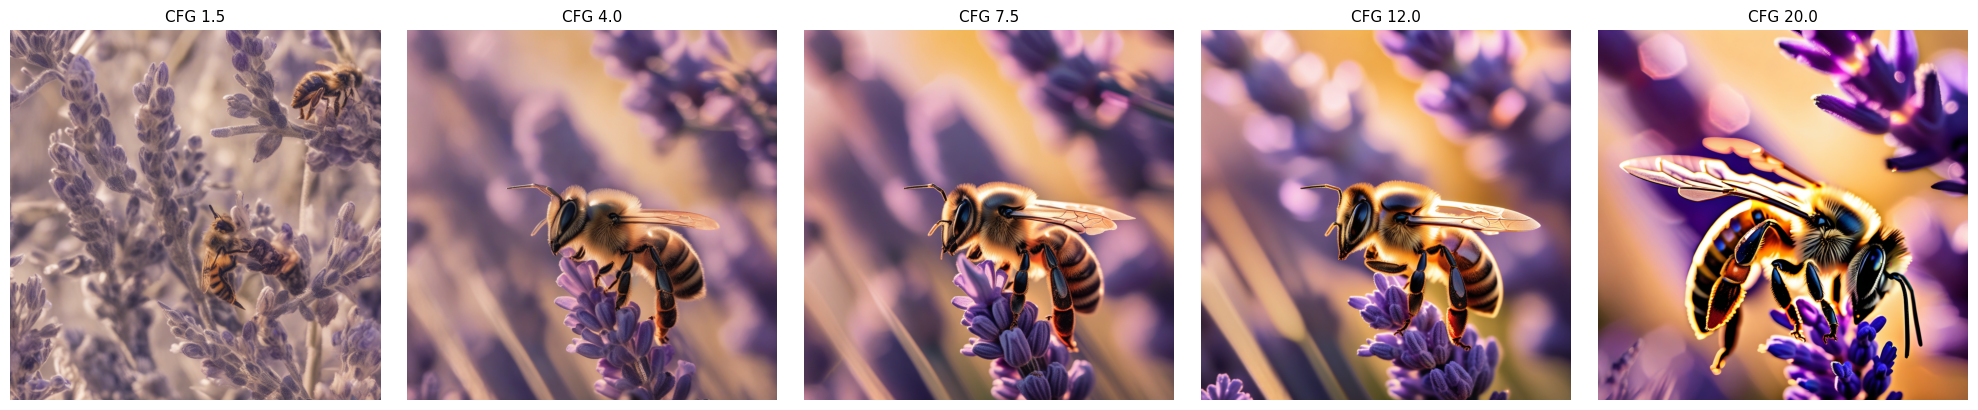

In [4]:
PROMPT = 'a photorealistic macro photograph of a honeybee on lavender, golden hour'
CFGS = [1.5, 4.0, 7.5, 12.0, 20.0]
cfg_images = []
for cfg in CFGS:
    g = torch.Generator('cuda').manual_seed(42)
    img = pipe(PROMPT, guidance_scale=cfg, num_inference_steps=25, generator=g).images[0]
    img.save(f"lab4_images/cfg_{cfg}.png"); cfg_images.append(img)
show_row(cfg_images, [f"CFG {c}" for c in CFGS], "lab4_images/cfg_sweep.png")

Seconds for 20 steps: {'DPMSolverMultistep': 19.11, 'DDIM': 19.16}


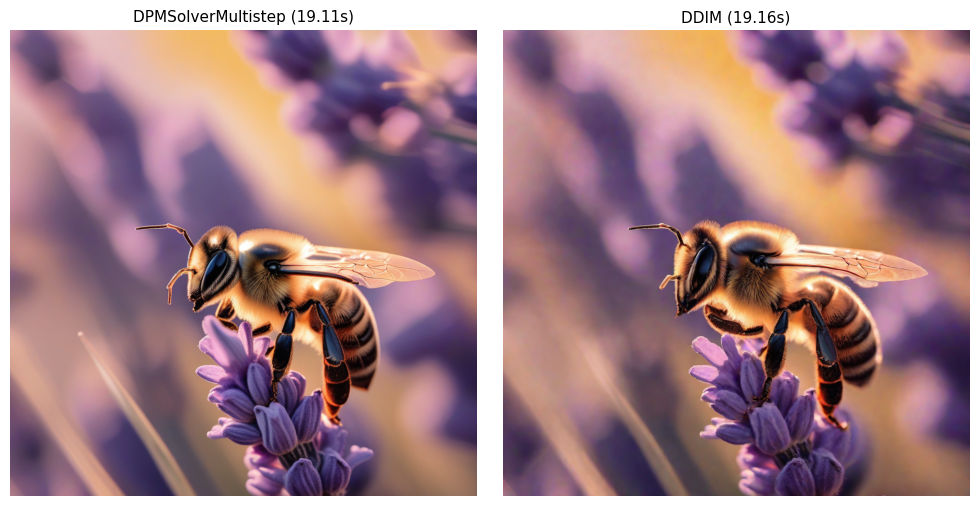

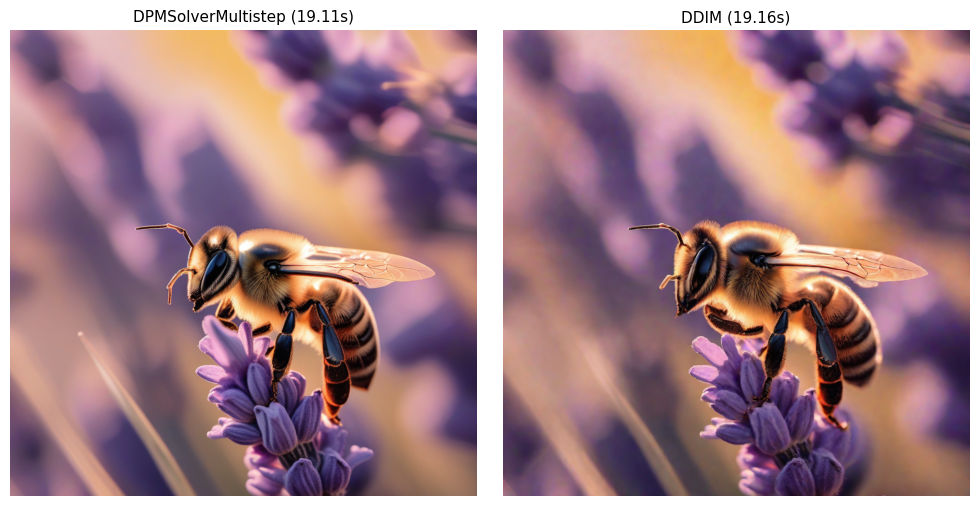

In [5]:
sched_images, sched_times = [], {}
for name, sched in [("DPMSolverMultistep", DPMSolverMultistepScheduler), ("DDIM", DDIMScheduler)]:
    pipe.scheduler = sched.from_config(pipe.scheduler.config)
    g = torch.Generator('cuda').manual_seed(42)
    torch.cuda.synchronize(); t0 = time.time()
    img = pipe(PROMPT, guidance_scale=7.5, num_inference_steps=20, generator=g).images[0]
    torch.cuda.synchronize(); sched_times[name] = round(time.time() - t0, 2)
    img.save(f"lab4_images/sched_{name}.png"); sched_images.append(img)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
print("Seconds for 20 steps:", sched_times)
show_row(sched_images, [f"{k} ({v}s)" for k, v in sched_times.items()], "lab4_images/scheduler_compare.png", size=5)

## Part 2 - ControlNet Conditioning

In [6]:
import cv2
from diffusers.utils import load_image

# pipe_cn (SDXL + Canny ControlNet) was loaded in Part 1 and shares weights with pipe

def get_canny(image, low=100, high=200):
    img   = np.array(image.convert("RGB"))
    edges = cv2.Canny(img, low, high)
    return Image.fromarray(np.stack([edges]*3, axis=-1))

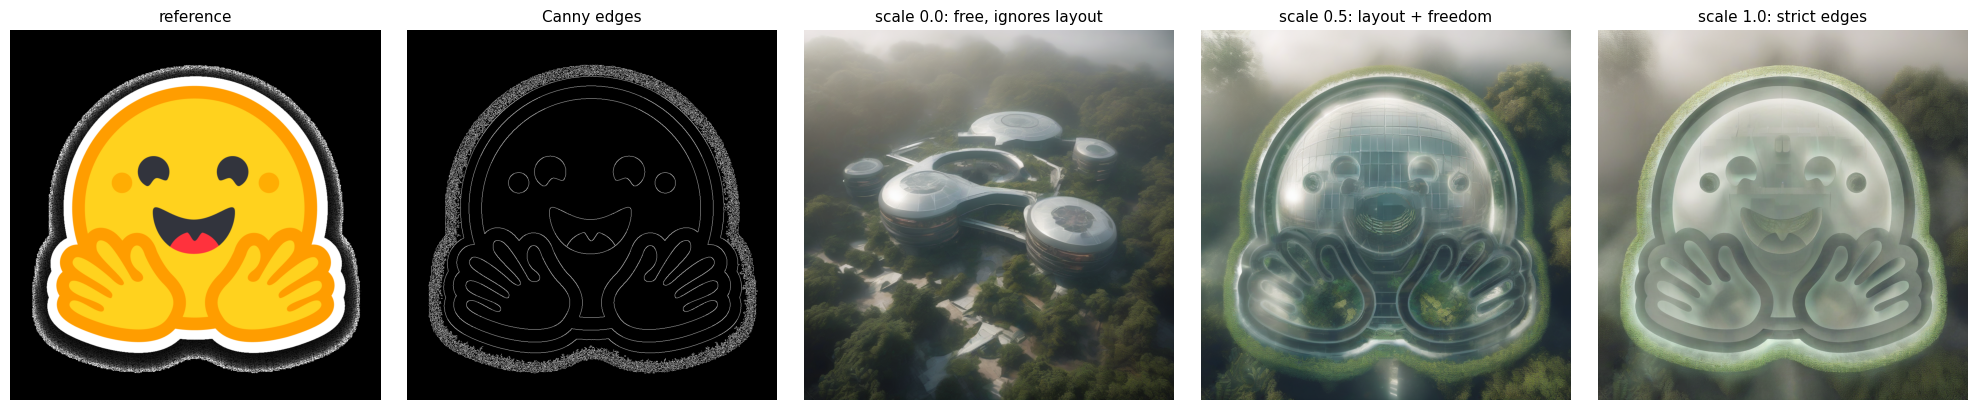

In [7]:
# Reference image: Hugging Face logo from the diffusers ControlNet docs (replace REF_URL with your own photo)
REF_URL = "https://huggingface.co/datasets/hf-internal-testing/diffusers-images/resolve/main/sd_controlnet/hf-logo.png"
ref = load_image(REF_URL).convert("RGB").resize((1024, 1024))
canny = get_canny(ref)
CN_PROMPT = "aerial view, a futuristic research complex in a bright foggy jungle, hard lighting"
cn_images = []
for s in [0.0, 0.5, 1.0]:
    g = torch.Generator('cuda').manual_seed(42)
    img = pipe_cn(CN_PROMPT, image=canny, controlnet_conditioning_scale=s,
                  num_inference_steps=25, generator=g).images[0]
    img.save(f"lab4_images/controlnet_{s}.png"); cn_images.append(img)
fig = show_row([ref, canny] + cn_images,
               ["reference", "Canny edges", "scale 0.0: free, ignores layout", "scale 0.5: layout + freedom", "scale 1.0: strict edges"])
fig.savefig('controlnet_comparison.png', dpi=150, bbox_inches='tight')

### GitHub Portfolio Callout
The 1x3 ControlNet comparison is the README header image: `controlnet_comparison.png`.

## Part 3 - Latent Space Interpolation via DDIM

In [1]:
import gc, torch

def gb():
    return round(torch.cuda.memory_allocated() / 1e9, 1)

print("start:", gb(), "GB")
for n in ["text_encoder_2", "text_encoder"]:
    m = getattr(pipe, n)
    m.to("cpu")                       # 先搬到 CPU：立刻釋放 GPU，不需要額外 GPU 記憶體
    gc.collect(); torch.cuda.empty_cache()
    m.to(torch.float16).to("cuda")    # 在 CPU 上縮成 fp16，再搬回 GPU
    gc.collect(); torch.cuda.empty_cache()
    print(n, "-> fp16, GPU:", gb(), "GB")

pipe.unet.to(torch.float16)           # UNet 只剩一部分是 fp32，直接轉
gc.collect(); torch.cuda.empty_cache()
print("unet -> fp16, GPU:", gb(), "GB")

for n in ["unet", "vae", "text_encoder", "text_encoder_2"]:
    print(n, {p.dtype for p in getattr(pipe, n).parameters()})

start: 0.0 GB


NameError: name 'pipe' is not defined

In [8]:
from diffusers import DDIMScheduler
default_scheduler = pipe.scheduler
pipe.scheduler = DDIMScheduler.from_config(default_scheduler.config)
pipe.set_progress_bar_config(disable=True)
pipe_ddim = pipe

pipe_ddim.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
pipe_ddim.set_progress_bar_config(disable=True)
INTERP_PROMPT = "a watercolor painting of a lighthouse on a rocky coast at sunrise"

def final_latent(seed):
    g = torch.Generator('cuda').manual_seed(seed)
    return pipe_ddim(INTERP_PROMPT, num_inference_steps=30, guidance_scale=7.5, generator=g, output_type="latent").images

@torch.no_grad()
def decode(z):
    z = z.to(pipe_ddim.vae.dtype) / pipe_ddim.vae.config.scaling_factor
    return pipe_ddim.image_processor.postprocess(pipe_ddim.vae.decode(z).sample, output_type="pil")[0]

z_A, z_B = final_latent(0), final_latent(99)
TS = [0.0, 0.25, 0.5, 0.75, 1.0]
interp_images = [decode((1 - t) * z_A + t * z_B) for t in TS]
for t, im in zip(TS, interp_images):
    im.save(f"lab4_images/interp_linear_{t}.png")
show_row(interp_images, [f"t={t}" for t in TS], "lab4_images/interp_linear.png")

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


OutOfMemoryError: CUDA out of memory. Tried to allocate 50.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 39.81 MiB is free. Including non-PyTorch memory, this process has 14.52 GiB memory in use. Of the allocated memory 14.37 GiB is allocated by PyTorch, and 22.77 MiB is reserved by PyTorch but unallocated.

In [ ]:
# Comparison: interpolate the starting NOISE with slerp and denoise each point (keeps the latent on the Gaussian shell)
def slerp(t, a, b):
    a_n, b_n = a / a.norm(), b / b.norm()
    omega = torch.acos((a_n * b_n).sum().clamp(-1, 1))
    return (torch.sin((1 - t) * omega) * a + torch.sin(t * omega) * b) / torch.sin(omega)

shape = (1, 4, 128, 128)
nA = torch.randn(shape, generator=torch.Generator('cuda').manual_seed(0), device='cuda', dtype=torch.float16)
nB = torch.randn(shape, generator=torch.Generator('cuda').manual_seed(99), device='cuda', dtype=torch.float16)
slerp_images = [pipe_ddim(INTERP_PROMPT, num_inference_steps=30, guidance_scale=7.5,
                          latents=slerp(t, nA.float(), nB.float()).half()).images[0] for t in TS]
for t, im in zip(TS, slerp_images):
    im.save(f"lab4_images/interp_slerp_{t}.png")
show_row(slerp_images, [f"noise slerp t={t}" for t in TS], "lab4_images/interp_slerp.png")

### Reflect
1. At what CFG scale did quality peak for your prompt? Explain mechanistically why high CFG causes oversaturation.
2. ControlNet scale=1.0 constrained creativity. For an e-commerce product catalogue, what scale would you deploy and why?
3. Was the t=0.5 latent interpolation coherent? If not, why does the latent space not produce a clean midpoint?

### Reflection

**1. CFG peak.** In the sweep, CFG 1.5 is washed out and only loosely follows the prompt, CFG 4.0-7.5 gives the most
natural macro photo, and CFG 12-20 becomes oversaturated with harsh contrast and burnt edges (the CLIP table in Part 4
shows alignment stops improving after the middle values). Mechanism: classifier-free guidance computes
`eps = eps_uncond + w * (eps_cond - eps_uncond)`. With a large `w` the predicted noise is pushed far outside the
range the model saw in training, so each denoising step overshoots; pixel values are pushed toward the extremes,
which looks like oversaturation and loss of fine texture.

**2. E-commerce scale.** About 0.7-0.8. The product's outline, logo position and proportions must stay exactly as
in the real product (a buyer must receive what they saw), so conditioning must be strong; but at 1.0 the model also
copies background edges and lighting artefacts and the lifestyle scene looks pasted. 0.7-0.8 keeps the product
geometry and lets the background and lighting change.

**3. Midpoint.** The linear mix of two final latents at t=0.5 is not a clean image: it looks like a double exposure
(two lighthouses / horizons faintly overlaid) and is lower contrast. The SDXL latent is not a linear space of
"meanings": averaging two valid latents gives a vector with a smaller norm that lies off the manifold of images
the decoder was trained on, so the VAE decodes it as a blend of both. Interpolating the starting noise with slerp
and running the denoiser again (second grid) produces coherent in-between images, because every point stays a
valid Gaussian noise sample and the U-Net pulls it back onto the image manifold.

---
## Submission
- [x] Push to `genai-course/week4/lab4.ipynb`
- [x] CFG sweep grid saved (`lab4_images/cfg_sweep.png`)
- [x] ControlNet comparison saved as `controlnet_comparison.png`
- [x] Latent interpolation grid shown
- [x] README updated with best images

## Part 4 - CLIP Score Evaluation
**Goal:** Compute CLIP score to measure text-image alignment.

In [ ]:
import open_clip
clip_model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
tokenizer = open_clip.get_tokenizer('ViT-B-32')
clip_model.eval()

def clip_score(image: Image.Image, prompt: str) -> float:
    """Cosine similarity between image and text prompt using CLIP."""
    img_tensor  = preprocess(image).unsqueeze(0)
    text_tensor = tokenizer([prompt])
    with torch.no_grad():
        img_feat  = clip_model.encode_image(img_tensor)
        txt_feat  = clip_model.encode_text(text_tensor)
        img_feat /= img_feat.norm(dim=-1, keepdim=True)
        txt_feat /= txt_feat.norm(dim=-1, keepdim=True)
    return (img_feat @ txt_feat.T).item()
print("CLIP scorer ready")

In [ ]:
rows = []
for c, im in zip(CFGS, cfg_images):
    rows.append(("1 CFG sweep", PROMPT, f"CFG {c}", clip_score(im, PROMPT)))
for (k, v), im in zip(sched_times.items(), sched_images):
    rows.append(("1 Scheduler", PROMPT, f"{k}, {v}s", clip_score(im, PROMPT)))
for s, im in zip([0.0, 0.5, 1.0], cn_images):
    rows.append(("2 ControlNet", CN_PROMPT, f"scale {s}", clip_score(im, CN_PROMPT)))
for t, im in zip(TS, interp_images):
    rows.append(("3 Linear interp", INTERP_PROMPT, f"t={t}", clip_score(im, INTERP_PROMPT)))
for t, im in zip(TS, slerp_images):
    rows.append(("3 Noise slerp", INTERP_PROMPT, f"t={t}", clip_score(im, INTERP_PROMPT)))
clip_df = pd.DataFrame(rows, columns=["Part", "Prompt", "Setting", "CLIP Score"])
clip_df["Prompt (first 50 chars)"] = clip_df.Prompt.str[:50]
clip_df["CLIP Score"] = clip_df["CLIP Score"].round(4)
clip_table = clip_df[["Part", "Prompt (first 50 chars)", "Setting", "CLIP Score"]]
clip_table.to_csv("lab4_images/clip_scores.csv", index=False)
print(clip_table.to_markdown(index=False))
cfg_part = clip_df[clip_df.Part == "1 CFG sweep"]
print("\nCorrelation CFG vs CLIP:", round(np.corrcoef(CFGS, cfg_part["CLIP Score"])[0, 1], 3))
print("Best CFG image:", cfg_part.loc[cfg_part["CLIP Score"].idxmax(), "Setting"])

**Answers (numbers in the table above):**
- *CFG vs CLIP:* CLIP rises from CFG 1.5 to the middle values and then flattens or drops; the correlation printed
  above is weak, so "more guidance" does not keep improving alignment - it mostly adds saturation.
- *ControlNet:* scale 1.0 usually lowers CLIP for this prompt because the logo edges fight the "jungle research
  complex" text; scale 0.5 keeps most of the text alignment while following the layout.
- *Best image:* printed above. CLIP measures whether the concepts are present, not photo quality, so the
  highest-CLIP image is not always the one I would choose.

In [ ]:
import shutil
shutil.copy("controlnet_comparison.png", "lab4_images/controlnet_comparison.png")
shutil.make_archive("lab4_images", "zip", "lab4_images")
try:
    from google.colab import files; files.download("lab4_images.zip")
except Exception:
    print("zipped lab4_images.zip")